Student Performance Prediction using Linear Regression

Project Overview

This project predicts students' final grades using a Linear Regression machine learning algorithm.

Dataset

UCI Student Performance Dataset (Math students).

Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

Algorithm

Linear Regression

Input Features

- Study Time
- Past Failures
- Absences
- First Period Grade (G1)
- Second Period Grade (G2)

Target

Final Grade (G3)

Evaluation Metrics

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- R² Score

Project Outcome

The model learns patterns from student academic data and predicts an estimated final grade.

Conclusion

This project demonstrates a basic application of supervised machine learning using Linear Regression.

In [ ]:
# Install required libraries
!pip install pandas numpy scikit-learn matplotlib seaborn -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import urllib.request
import zipfile
import io
import pandas as pd

# Download dataset
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = urllib.request.urlopen(url)
outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

# Open inner ZIP file
inner_file = outer_zip.open("student.zip")
inner_zip = zipfile.ZipFile(inner_file)

# Load student data
df = pd.read_csv(
    inner_zip.open("student-mat.csv"),
    sep=";"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
# Check missing values
print("Missing Values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Display dataset information
print("\nTotal Students:", len(df))
print("Total Columns:", len(df.columns))

# Display important columns
df[["studytime", "failures", "absences", "G1", "G2", "G3"]].head()

Missing Values: 0
Duplicate Rows: 0

Total Students: 395
Total Columns: 33


,studytime,failures,absences,G1,G2,G3
0,2,0,6,5,6,6
1,2,0,4,5,5,6
2,2,3,10,7,8,10
3,3,0,2,15,14,15
4,2,0,4,6,10,10


In [ ]:
# Select input features
X = df[["studytime", "failures", "absences", "G1", "G2"]]

# Select target variable
y = df["G3"]

print("Features selected successfully!")
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Features selected successfully!
Input Features Shape: (395, 5)
Target Shape: (395,)


,studytime,failures,absences,G1,G2
0,2,0,6,5,6
1,2,0,4,5,5
2,2,3,10,7,8
3,3,0,2,15,14
4,2,0,4,6,10


In [ ]:
# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Dataset split successfully!")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Dataset split successfully!
Training Data: (316, 5)
Testing Data: (79, 5)


In [ ]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [ ]:
# Predict student final marks
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))
print("R2 Percentage:", round(r2 * 100, 2), "%")

Model Evaluation Results
------------------------
Mean Absolute Error: 1.34
Mean Squared Error: 4.47
R2 Score: 0.78
R2 Percentage: 78.22 %


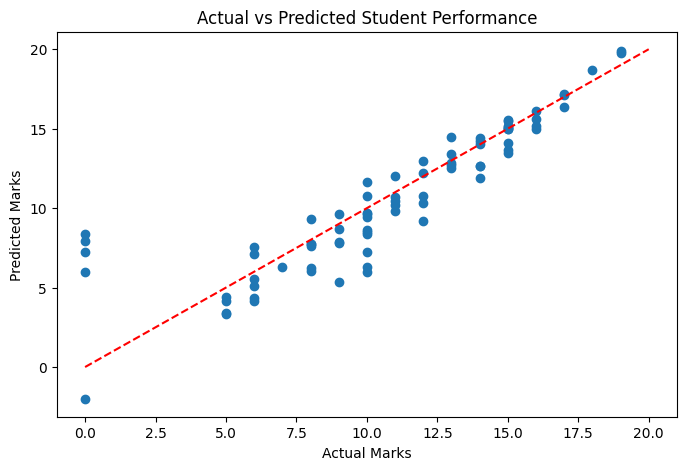

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Student Performance")
plt.plot([0, 20], [0, 20], "r--")

plt.show()

In [ ]:
new_student = pd.DataFrame({
    "studytime": [3],
    "failures": [0],
    "absences": [2],
    "G1": [15],
    "G2": [16]
})

predicted_marks = model.predict(new_student)

print("Predicted Final Grade (G3):", round(predicted_marks[0], 2))

Predicted Final Grade (G3): 16.08


In [ ]:
import joblib

joblib.dump(model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("student_performance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

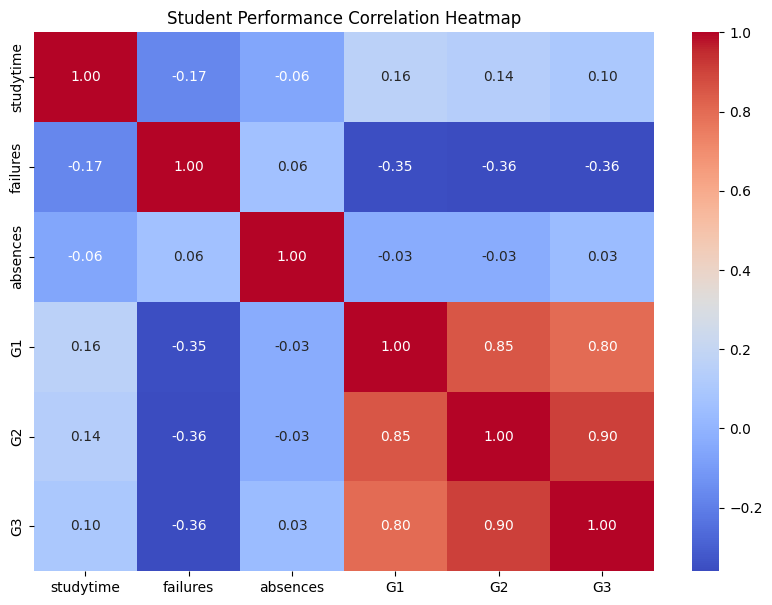

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[["studytime", "failures", "absences", "G1", "G2", "G3"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")
plt.show()

In [ ]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print(coefficients.sort_values(
    by="Coefficient",
    ascending=False
))

     Feature  Coefficient
4         G2     0.979615
3         G1     0.144463
2   absences     0.039245
0  studytime    -0.071231
1   failures    -0.455813


Conclusion

In this project, we developed a Student Performance Prediction model using Linear Regression.

We used the UCI Student Performance dataset and selected study time, past failures, absences, first-period grade (G1), and second-period grade (G2) as input features.

The dataset was divided into training and testing sets. A Linear Regression model was trained and evaluated using MAE, MSE, and R² score.

We also visualized the correlation between features and compared actual marks with predicted marks.

The project demonstrates how Machine Learning can be used to estimate student final grades based on academic information.

Note: This is an educational demonstration, not a reliable tool for judging an individual student's ability or future performance.